# Where the Card Users Are

The app offers a payment card linked to the user's crypto and euro balances. This notebook looks at the card users by country:

1. where cards are ordered,
2. how far each country gets from ordering a card to using it,
3. which payments get declined, and why,
4. how concentrated the money is.

**Data:** synthetic, generated by [make_cards.py](make_cards.py): about 7,000 cards ordered in 2024 and their payments.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.spines.top": False, "axes.spines.right": False})

In [2]:
cards = pd.read_csv("cards.csv", parse_dates=["ordered"])
payments = pd.read_csv("card_payments.csv.gz", parse_dates=["date"]).merge(cards[["card_id", "country", "region"]], on="card_id")
print(f"{len(cards):,} cards in {cards.country.nunique()} countries, {len(payments):,} payments")
cards.status.value_counts()

7,134 cards in 20 countries, 24,074 payments


status
active                        3011
delivered, never activated    2849
not processed                  567
closed                         341
in delivery                    220
blocked                        146
Name: count, dtype: int64

## 1. Where cards are ordered

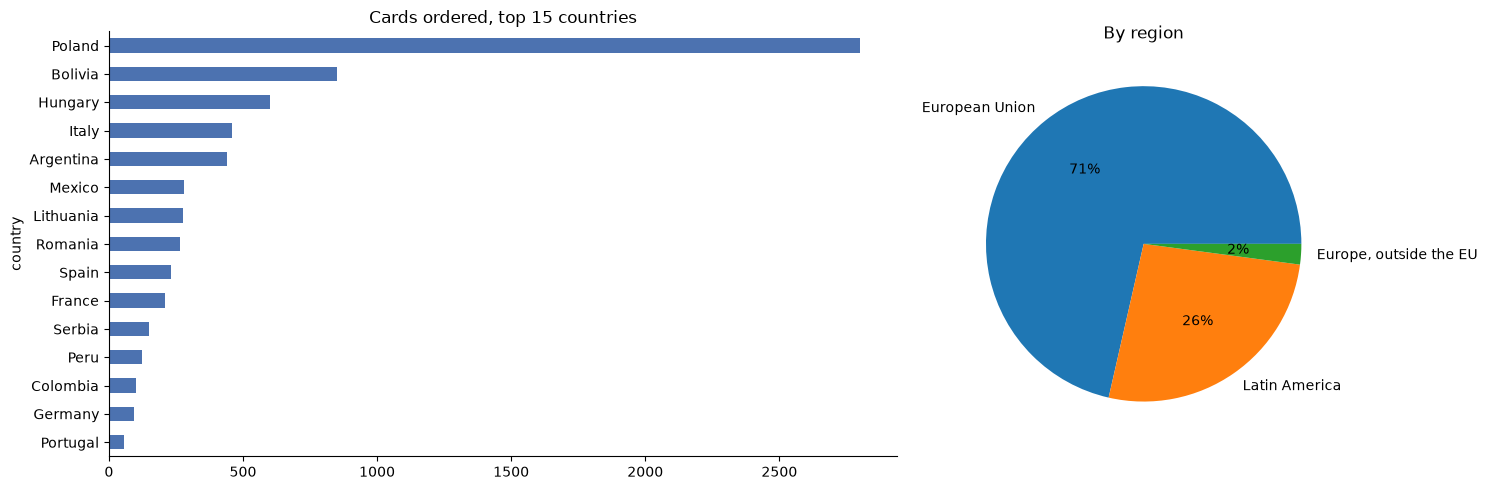

Poland alone: 39% of all cards


In [3]:
by_country = cards.country.value_counts()
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [2, 1]})
by_country.head(15)[::-1].plot.barh(ax=axes[0], color="#4c72b0", title="Cards ordered, top 15 countries")
cards.region.value_counts().plot.pie(ax=axes[1], autopct="%.0f%%", title="By region", ylabel="")
plt.tight_layout()
plt.show()
print(f"Poland alone: {by_country.iloc[0] / len(cards):.0%} of all cards")

## 2. From ordering a card to using it

A card goes through several stages: it is checked and sent (or not processed), delivered, and then activated by the user. A card that arrives but is never activated is a lost customer: the app paid to make and ship it.

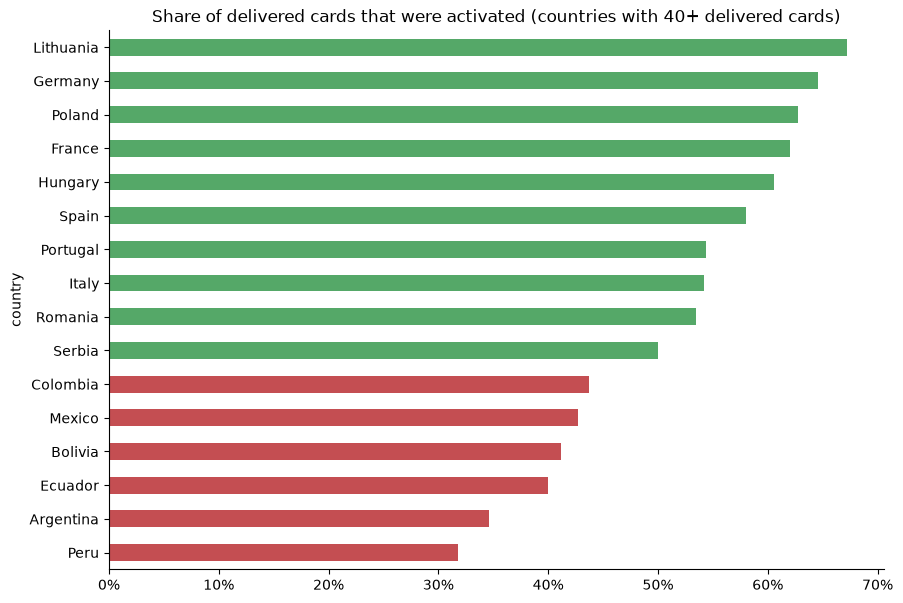

In [4]:
delivered = cards[~cards.status.isin(["in delivery", "not processed"])]
funnel = delivered.assign(activated=delivered.status.isin(["active", "blocked", "closed"])).groupby("country").agg(
    delivered=("card_id", "size"), activated=("activated", "mean"))
funnel = funnel[funnel.delivered >= 40].sort_values("activated")
ax = funnel.activated.plot.barh(figsize=(10, 7), color=np.where(funnel.activated < 0.5, "#c44e52", "#55a868"),
                                title="Share of delivered cards that were activated (countries with 40+ delivered cards)")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
plt.show()

In [5]:
delivered.assign(activated=delivered.status.isin(["active", "blocked", "closed"])).groupby("region").activated.mean().round(3).rename("activated")

region
Europe, outside the EU    0.500
European Union            0.611
Latin America             0.395
Name: activated, dtype: float64

## 3. Declined payments

In [6]:
decline = payments.groupby("region").result.apply(lambda r: (r == "declined").mean())
print((decline * 100).round(1).rename("declined, %").to_string())
reasons = pd.crosstab(payments[payments.result == "declined"].decline_reason, payments[payments.result == "declined"].region, normalize="columns")
reasons.round(2)

region
Europe, outside the EU    16.0
European Union             9.8
Latin America             22.7


region,"Europe, outside the EU",European Union,Latin America
decline_reason,,,
blocked by issuer,0.21,0.26,0.48
insufficient funds,0.54,0.49,0.32
merchant not supported,0.13,0.11,0.09
wrong PIN,0.13,0.14,0.11


## 4. How concentrated the money is

In [7]:
money = cards[cards.deposits_eur > 0].deposits_eur.sort_values(ascending=False)
top1 = money.iloc[: len(money) // 100].sum() / money.sum()
top10 = money.iloc[: len(money) // 10].sum() / money.sum()
print(f"card users with deposits: {len(money):,}; the top 1% hold {top1:.0%} of the deposits, the top 10% hold {top10:.0%}")

per_user = cards[cards.deposits_eur > 0].groupby("country").agg(users=("card_id", "size"), median_deposit=("deposits_eur", "median"),
                                                                 total=("deposits_eur", "sum"))
per_user["share of all deposits"] = per_user.total / per_user.total.sum()
per_user.sort_values("total", ascending=False).head(10).round(2)

card users with deposits: 3,498; the top 1% hold 49% of the deposits, the top 10% hold 74%


,users,median_deposit,total,share of all deposits
country,,,,
Poland,1566,419.60,2905652.90,0.49
France,116,482.84,745724.27,0.13
Italy,226,556.91,470788.76,0.08
Hungary,318,388.41,418410.51,0.07
Lithuania,162,360.52,313654.54,0.05
Spain,116,562.08,270841.75,0.05
Bolivia,314,118.21,128719.03,0.02
Portugal,25,457.96,124917.34,0.02
Romania,124,284.09,113588.34,0.02


## Results

- Poland alone accounts for 39% of the cards. Europe and Latin America make up most of the rest, with Bolivia, Hungary, Italy, and Argentina next.
- Many cards are delivered and never used: only about 40% of delivered cards in Latin America get activated, against 61% in the EU. Every unused card was made and shipped for nothing, so activation reminders, or asking for a deposit before shipping, would pay off most in Latin America.
- Payments are declined more than twice as often in Latin America (23%) as in the EU (10%). There, nearly half the declines are blocks by the card issuer, while in Europe the main reason is insufficient funds: the first is a problem the app can work on with its card issuer, the second is ordinary behavior.
- The money is concentrated in a few users: the top 1% of card users hold about half of all deposits, and the top 10% about three-quarters. Poland holds half the deposits; France, with only 116 card users, holds 13%, because of a few large depositors. Country totals that small move a lot with one or two people, so they are better tracked as medians.

## Tools

Python, pandas, NumPy, matplotlib